# Taller Final de Minería de Datos
## Segmentación de clientes con K-Means

**Dataset:** Mall Customers Dataset (200 clientes)  
**Archivo local:** `Mall_Customers.csv`  
**Objetivo general:** construir un modelo de segmentación de clientes con K-Means, evaluarlo con el método del codo y el coeficiente de silueta, e interpretar los grupos desde una perspectiva de negocio.

**Nombre:** Luna Gabriela Mideros Botina

---

El modelo utiliza las variables `Annual Income (k$)` y `Spending Score (1-100)`; la edad y el género se usan para describir los segmentos.


## 0. Configuración del entorno

Se importan las librerías y se fija una semilla para que los resultados sean reproducibles.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.style.use("ggplot")
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")

RANDOM_STATE = 42
DATA_PATH = Path("Mall_Customers.csv")
print("Archivo encontrado:", DATA_PATH.exists())

Archivo encontrado: True


## Parte 1 — Exploración de Datos

**Actividades:** cargar el dataset, identificar las variables relevantes y realizar un análisis descriptivo básico.

**Preguntas:**
1. ¿Qué variables son más adecuadas para segmentar clientes?
2. ¿Se identifican valores atípicos?
3. ¿Qué tipo de relaciones se observan entre las variables?

### 1.1 Carga del dataset y estructura

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"El dataset tiene {df.shape[0]} filas y {df.shape[1]} columnas.")
display(df.head(10))

El dataset tiene 200 filas y 5 columnas.


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
calidad = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Valores nulos": df.isna().sum(),
    "Valores unicos": df.nunique(),
})
display(calidad)
print("Filas duplicadas:", df.duplicated().sum())
print("CustomerID duplicados:", df["CustomerID"].duplicated().sum())

,Tipo,Valores nulos,Valores unicos
CustomerID,int64,0,200
Gender,str,0,2
Age,int64,0,51
Annual Income (k$),int64,0,64
Spending Score (1-100),int64,0,84


Filas duplicadas: 0
CustomerID duplicados: 0


### 1.2 Análisis descriptivo básico

In [4]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
CustomerID,200.00,100.50,57.88,1.00,50.75,100.50,150.25,200.00
Age,200.00,38.85,13.97,18.00,28.75,36.00,49.00,70.00
Annual Income (k$),200.00,60.56,26.26,15.00,41.50,61.50,78.00,137.00
Spending Score (1-100),200.00,50.20,25.82,1.00,34.75,50.00,73.00,99.00


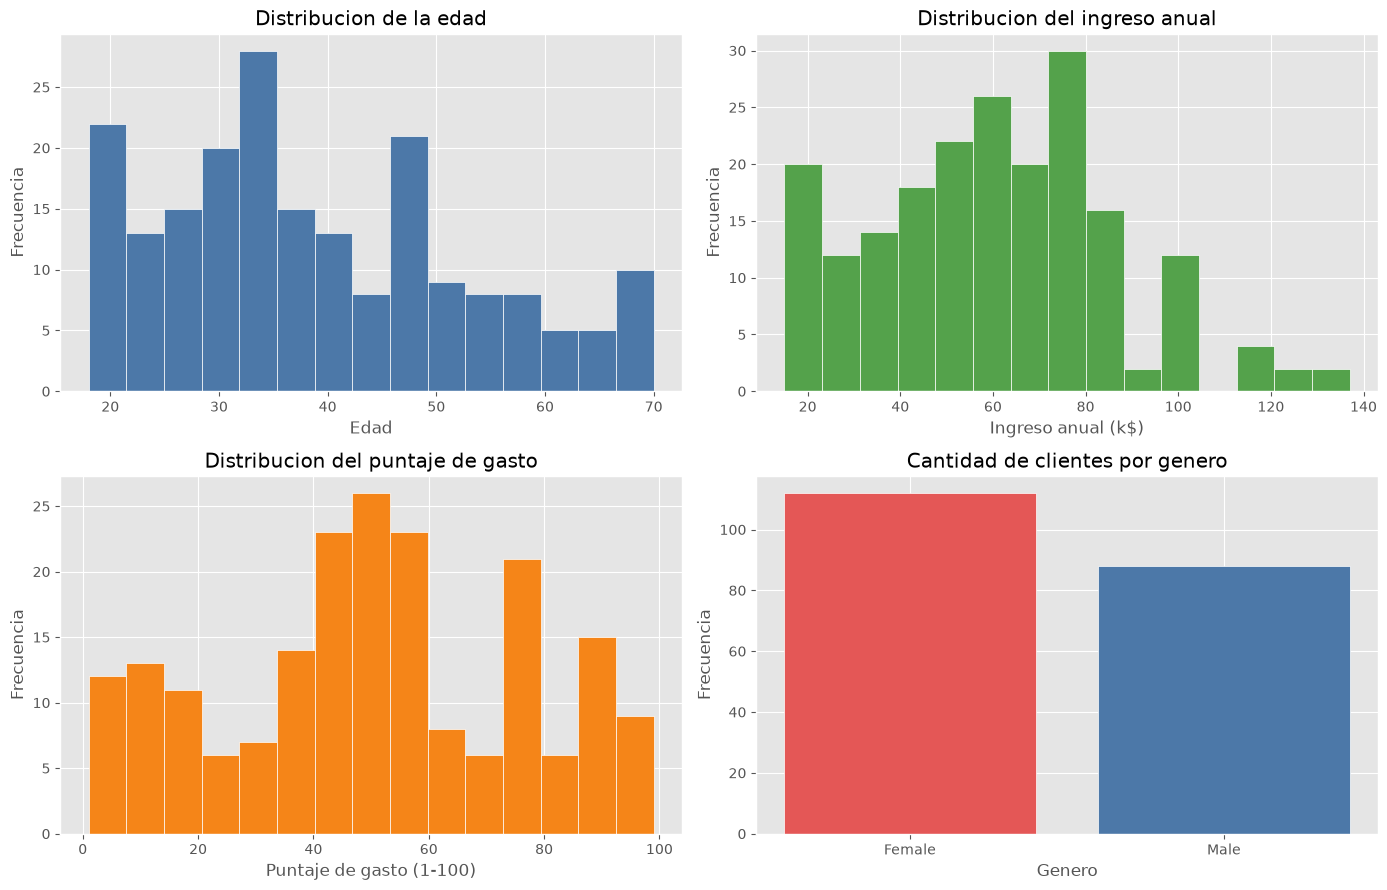

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].hist(df["Age"], bins=15, color="#4C78A8", edgecolor="white")
axes[0, 0].set_title("Distribucion de la edad")
axes[0, 0].set_xlabel("Edad")
axes[0, 0].set_ylabel("Frecuencia")

axes[0, 1].hist(df["Annual Income (k$)"], bins=15, color="#54A24B", edgecolor="white")
axes[0, 1].set_title("Distribucion del ingreso anual")
axes[0, 1].set_xlabel("Ingreso anual (k$)")
axes[0, 1].set_ylabel("Frecuencia")

axes[1, 0].hist(df["Spending Score (1-100)"], bins=15, color="#F58518", edgecolor="white")
axes[1, 0].set_title("Distribucion del puntaje de gasto")
axes[1, 0].set_xlabel("Puntaje de gasto (1-100)")
axes[1, 0].set_ylabel("Frecuencia")

conteo_genero = df["Gender"].value_counts()
axes[1, 1].bar(conteo_genero.index, conteo_genero.values, color=["#E45756", "#4C78A8"], edgecolor="white")
axes[1, 1].set_title("Cantidad de clientes por genero")
axes[1, 1].set_xlabel("Genero")
axes[1, 1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

### 1.3 Identificación de valores atípicos

Se aplica la regla de 1.5 veces el rango intercuartílico (IQR).

In [6]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

variables_numericas = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
resumen_outliers = []

for columna in variables_numericas:
    limite_inferior, limite_superior = limites_iqr(df[columna])
    cantidad = int(((df[columna] < limite_inferior) | (df[columna] > limite_superior)).sum())
    resumen_outliers.append({
        "Variable": columna,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Valores atipicos": cantidad,
    })

display(pd.DataFrame(resumen_outliers).round(2))

lim_ing_inf, lim_ing_sup = limites_iqr(df["Annual Income (k$)"])
posibles_atipicos = df.loc[
    (df["Annual Income (k$)"] < lim_ing_inf) | (df["Annual Income (k$)"] > lim_ing_sup),
    ["CustomerID", "Gender", "Age", "Annual Income (k$)", "Spending Score (1-100)"],
]
print("Clientes con ingreso fuera de los limites:")
display(posibles_atipicos)

,Variable,Limite inferior,Limite superior,Valores atipicos
0,Age,-1.62,79.38,0
1,Annual Income (k$),-13.25,132.75,2
2,Spending Score (1-100),-22.62,130.38,0


Clientes con ingreso fuera de los limites:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


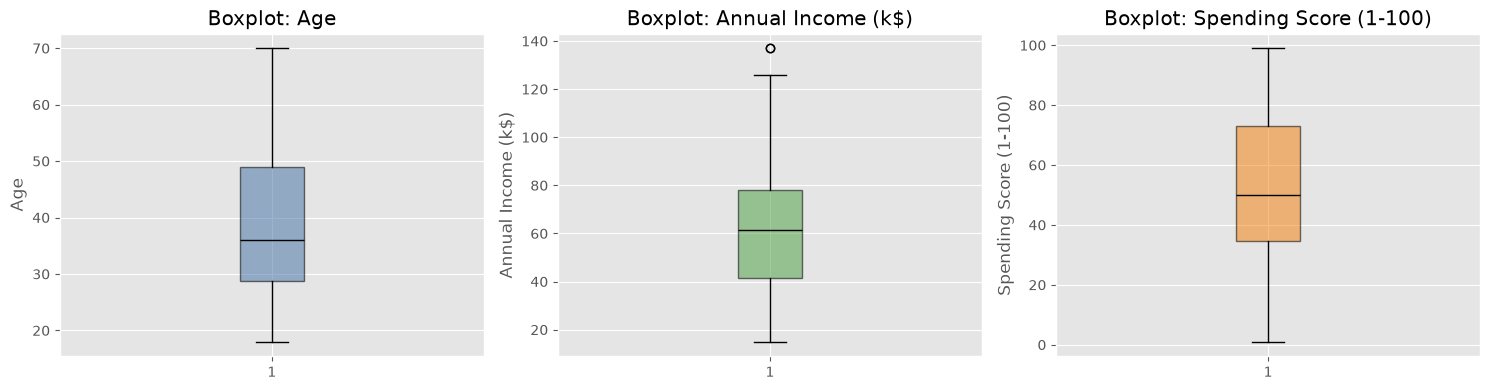

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, columna, color in zip(
    axes,
    variables_numericas,
    ["#4C78A8", "#54A24B", "#F58518"],
):
    ax.boxplot(df[columna], orientation="vertical", patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.55),
               medianprops=dict(color="black"))
    ax.set_title(f"Boxplot: {columna}")
    ax.set_ylabel(columna)
plt.tight_layout()
plt.show()

### 1.4 Relaciones entre variables

,Age,Annual Income (k$),Spending Score (1-100)
Age,1.00,-0.01,-0.33
Annual Income (k$),-0.01,1.00,0.01
Spending Score (1-100),-0.33,0.01,1.00


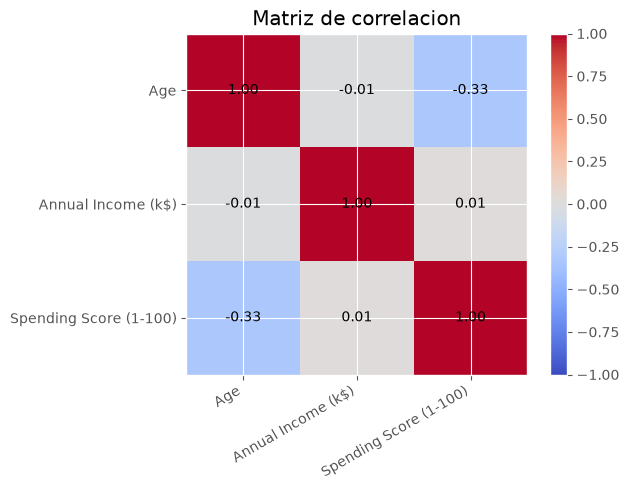

In [8]:
correlaciones = df[variables_numericas].corr()
display(correlaciones.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
imagen = ax.imshow(correlaciones, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlaciones.columns)))
ax.set_yticks(range(len(correlaciones.columns)))
ax.set_xticklabels(correlaciones.columns, rotation=30, ha="right")
ax.set_yticklabels(correlaciones.columns)
for i in range(len(correlaciones)):
    for j in range(len(correlaciones)):
        ax.text(j, i, f"{correlaciones.iloc[i, j]:.2f}", ha="center", va="center", color="black")
ax.set_title("Matriz de correlacion")
fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

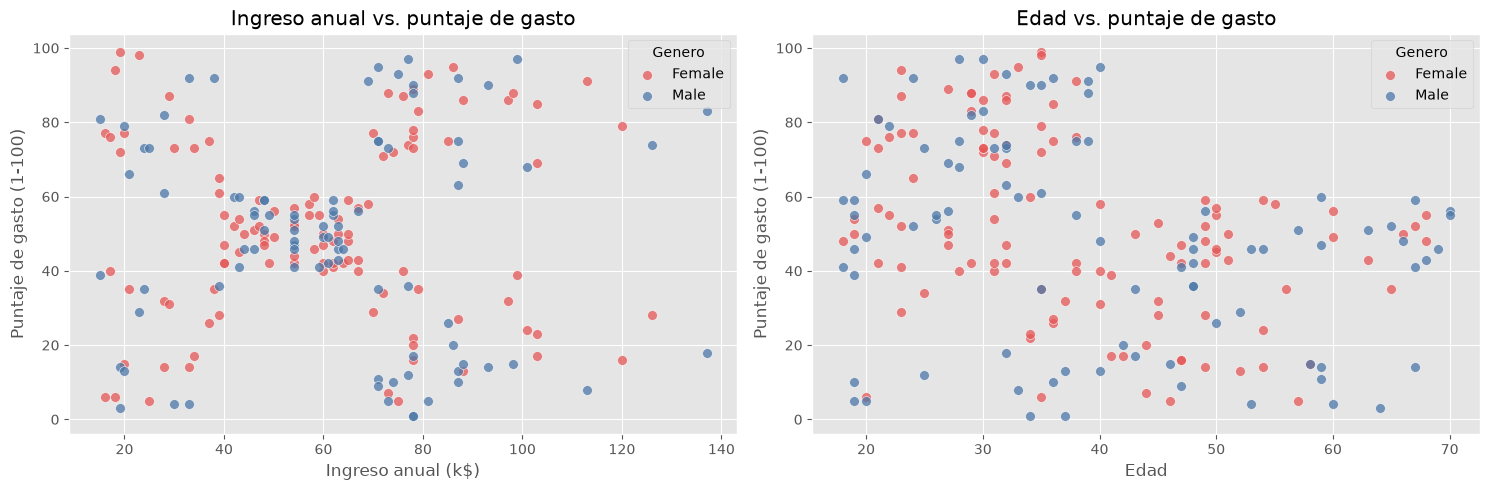

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colores_genero = {"Female": "#E45756", "Male": "#4C78A8"}

for genero, grupo in df.groupby("Gender"):
    axes[0].scatter(
        grupo["Annual Income (k$)"],
        grupo["Spending Score (1-100)"],
        label=genero,
        color=colores_genero[genero],
        alpha=0.75,
        s=50,
        edgecolors="white",
    )
axes[0].set_title("Ingreso anual vs. puntaje de gasto")
axes[0].set_xlabel("Ingreso anual (k$)")
axes[0].set_ylabel("Puntaje de gasto (1-100)")
axes[0].legend(title="Genero")

for genero, grupo in df.groupby("Gender"):
    axes[1].scatter(
        grupo["Age"],
        grupo["Spending Score (1-100)"],
        label=genero,
        color=colores_genero[genero],
        alpha=0.75,
        s=50,
        edgecolors="white",
    )
axes[1].set_title("Edad vs. puntaje de gasto")
axes[1].set_xlabel("Edad")
axes[1].set_ylabel("Puntaje de gasto (1-100)")
axes[1].legend(title="Genero")

plt.tight_layout()
plt.show()

### Respuestas — Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**

Las variables más adecuadas son **`Annual Income (k$)`** y **`Spending Score (1-100)`**, porque resumen las dos dimensiones clave para marketing: la **capacidad de compra** y la **propensión a gastar**. La edad aporta contexto para describir los segmentos, pero por sí sola separa menos a los clientes. `Gender` solo tiene dos categorías y no muestra una relación fuerte con el gasto; `CustomerID` es un identificador y no aporta información para agrupar.

**¿Se identifican valores atípicos?**

Con la regla IQR, la edad y el puntaje de gasto no presentan atípicos. En el ingreso anual aparecen **2 clientes con 137 k$**, por encima del límite superior de 132.75 k$. No parecen errores de captura: son clientes de ingreso alto y se conservan porque aportan información real. Su efecto en K-Means es limitado y el escalamiento reduce su influencia relativa.

**¿Qué tipo de relaciones se observan entre las variables?**

Las correlaciones lineales son débiles: ingreso–gasto ≈ **0.01**, edad–gasto ≈ **-0.327** y edad–ingreso ≈ **-0.012**. No existe una relación lineal fuerte que explique el gasto. Sin embargo, el diagrama de dispersión ingreso–gasto muestra **concentraciones o grupos naturales** (por ejemplo, alto ingreso con alto gasto, alto ingreso con bajo gasto, bajo ingreso con alto gasto). Esa estructura no lineal justifica el uso de K-Means.

## Parte 2 — Preprocesamiento

**Actividad:** aplicar normalización mediante `StandardScaler`.

**Pregunta:** ¿Por qué es necesario escalar las variables en el algoritmo K-Means?

In [10]:
FEATURES = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[FEATURES].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

comparacion_escala = pd.DataFrame({
    "Variable": FEATURES,
    "Media original": X.mean().to_numpy(),
    "Desviacion original": X.std(ddof=0).to_numpy(),
    "Media escalada": X_scaled.mean(axis=0),
    "Desviacion escalada": X_scaled.std(axis=0),
})
display(comparacion_escala.round(3))

print("Primeras filas antes del escalamiento:")
display(X.head())
print("Primeras filas despues del escalamiento:")
display(pd.DataFrame(X_scaled, columns=FEATURES).head())

,Variable,Media original,Desviacion original,Media escalada,Desviacion escalada
0,Annual Income (k$),60.56,26.20,-0.00,1.00
1,Spending Score (1-100),50.20,25.76,-0.00,1.00


Primeras filas antes del escalamiento:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


Primeras filas despues del escalamiento:


,Annual Income (k$),Spending Score (1-100)
0,-1.74,-0.43
1,-1.74,1.20
2,-1.70,-1.72
3,-1.70,1.04
4,-1.66,-0.40


### Respuesta — Parte 2

K-Means asigna cada cliente al centroide más cercano usando **distancia euclidiana**. Si las variables no están escaladas, el ingreso anual (que varía aproximadamente entre 15 y 137 k$) domina sobre el puntaje de gasto (que varía entre 1 y 100). El algoritmo terminaría agrupando principalmente por ingreso y el gasto quedaría casi ignorado.

`StandardScaler` transforma cada variable a media 0 y desviación estándar 1, de modo que ambas aportan con el mismo peso. Esto mejora la estabilidad del algoritmo, evita que una unidad de medida condicione los centroides y facilita comparar distancias entre variables.

## Parte 3 — Método del Codo

**Actividad:** construir la gráfica del método del codo para distintos valores de K.

**Preguntas:**
1. ¿Por qué valores cercanos a cero indican mejor ajuste?
2. ¿Cómo se identifica el punto óptimo de K?

In [11]:
inercias = []
for k in range(1, 11):
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

codo_df = pd.DataFrame({"K": list(range(1, 11)), "Inercia": inercias})
codo_df["Reduccion"] = codo_df["Inercia"].diff().abs()
display(codo_df.round(2))

,K,Inercia,Reduccion
0,1,400.00,NaN
1,2,269.69,130.31
2,3,157.70,111.99
3,4,108.92,48.78
4,5,65.57,43.35
5,6,55.06,10.51
6,7,44.86,10.19
7,8,37.23,7.64
8,9,32.39,4.84
9,10,29.98,2.41


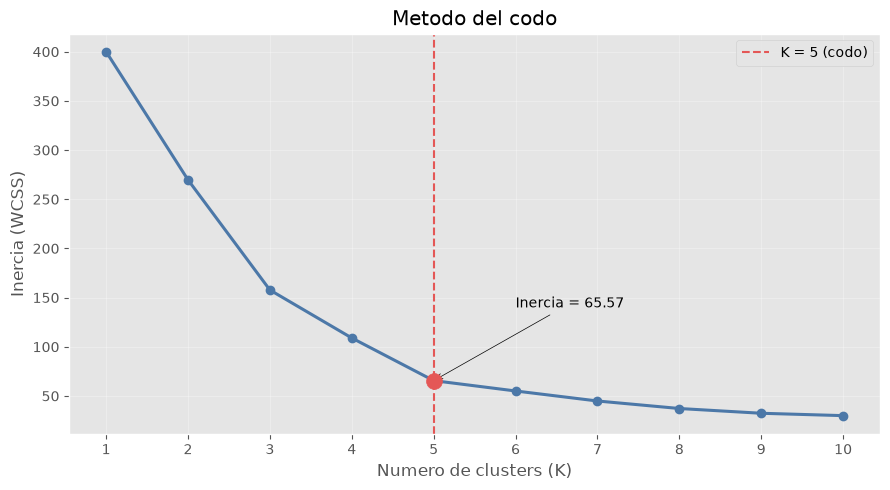

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(codo_df["K"], codo_df["Inercia"], marker="o", linewidth=2.2, color="#4C78A8")
ax.axvline(5, color="#E45756", linestyle="--", linewidth=1.5, label="K = 5 (codo)")
ax.scatter([5], [codo_df.loc[codo_df["K"] == 5, "Inercia"].iloc[0]],
           s=130, color="#E45756", zorder=5)
ax.annotate(
    f"Inercia = {codo_df.loc[codo_df['K'] == 5, 'Inercia'].iloc[0]:.2f}",
    xy=(5, codo_df.loc[codo_df["K"] == 5, "Inercia"].iloc[0]),
    xytext=(6.0, 140),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10,
)
ax.set_title("Metodo del codo")
ax.set_xlabel("Numero de clusters (K)")
ax.set_ylabel("Inercia (WCSS)")
ax.set_xticks(codo_df["K"])
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Respuestas — Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**

La inercia o **WCSS** (*Within-Cluster Sum of Squares*) es la suma de las distancias al cuadrado entre cada punto y el centroide de su cluster. Un valor más bajo significa clusters más compactos: los clientes están más cerca de su centroide. En el extremo, si K es igual al número de clientes, la inercia sería 0 porque cada cliente sería su propio centroide, pero ese modelo no segmenta nada. Por eso la inercia no se minimiza sin límite: debe equilibrarse con la interpretabilidad y con el número de clusters.

**¿Cómo se identifica el punto óptimo de K?**

Se busca el **codo**: el punto donde agregar un cluster más deja de reducir la inercia de forma importante. En la tabla, el paso de K=4 a K=5 reduce la inercia de 108.92 a 65.57 (una caída de 43.35), mientras que de K=5 a K=6 solo baja a 55.06 (una caída de 10.51). Esa desaceleración marca el codo en **K = 5**.

## Parte 4 — Coeficiente de Silueta

**Actividad:** calcular el coeficiente de silueta para distintos valores de K.

**Preguntas:**
1. ¿Qué mide el coeficiente de silueta?
2. ¿Qué significa un valor cercano a 1?
3. ¿Qué implica un valor cercano a 0 o negativo?
4. ¿Coincide el valor óptimo de K con el método del codo? Justifique.

In [13]:
resultados_silueta = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    etiquetas = modelo.fit_predict(X_scaled)
    puntaje = silhouette_score(X_scaled, etiquetas)
    resultados_silueta.append({"K": k, "Silueta": puntaje})

silueta_df = pd.DataFrame(resultados_silueta)
display(silueta_df.round(4))

mejor_silueta = silueta_df.loc[silueta_df["Silueta"].idxmax()]
print(f"Mejor K segun silueta: {int(mejor_silueta['K'])} con {mejor_silueta['Silueta']:.4f}")

,K,Silueta
0,2,0.32
1,3,0.47
2,4,0.49
3,5,0.55
4,6,0.54
5,7,0.53
6,8,0.46
7,9,0.46
8,10,0.44


Mejor K segun silueta: 5 con 0.5547


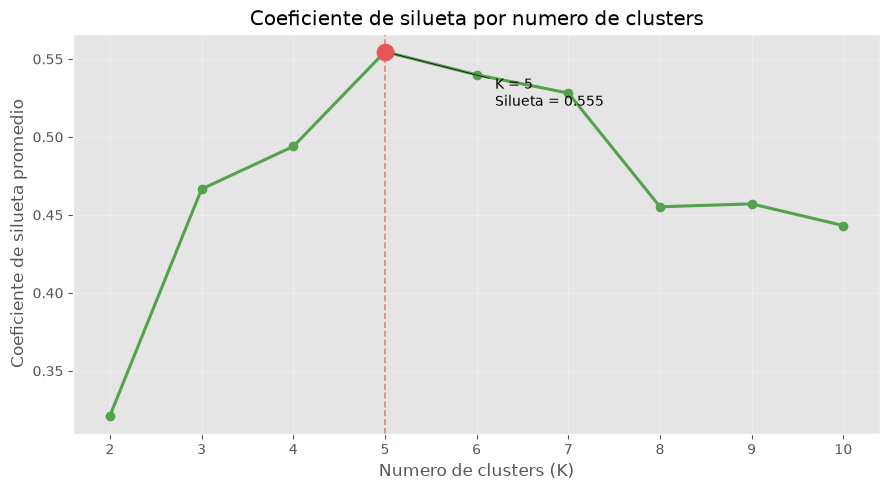

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(silueta_df["K"], silueta_df["Silueta"], marker="o", linewidth=2.2, color="#54A24B")
ax.scatter([mejor_silueta["K"]], [mejor_silueta["Silueta"]], s=150, color="#E45756", zorder=5)
ax.annotate(
    f"K = {int(mejor_silueta['K'])}\nSilueta = {mejor_silueta['Silueta']:.3f}",
    xy=(mejor_silueta["K"], mejor_silueta["Silueta"]),
    xytext=(6.2, 0.52),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10,
)
ax.axvline(5, color="#E45756", linestyle="--", linewidth=1.2, alpha=0.7)
ax.set_title("Coeficiente de silueta por numero de clusters")
ax.set_xlabel("Numero de clusters (K)")
ax.set_ylabel("Coeficiente de silueta promedio")
ax.set_xticks(silueta_df["K"])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Respuestas — Parte 4

**¿Qué mide el coeficiente de silueta?**

Mide simultáneamente la **cohesión** de cada punto con su propio cluster y la **separación** respecto al cluster más cercano. Para cada observación se calcula:

- `a` = distancia promedio a los demás puntos de su mismo cluster.
- `b` = distancia promedio a los puntos del cluster vecino más cercano.
- `s = (b - a) / max(a, b)`.

El coeficiente final es el promedio de `s` para todas las observaciones y varía entre -1 y 1.

**¿Qué significa un valor cercano a 1?**

El cliente está muy cerca de los miembros de su propio cluster y lejos de los demás. Indica clusters compactos y bien separados; el valor 1 sería una separación perfecta.

**¿Qué implica un valor cercano a 0 o negativo?**

Un valor cercano a **0** indica que el punto está en la frontera entre dos clusters o que hay solapamiento: no es claramente de un grupo ni de otro. Un valor **negativo** sugiere que el punto fue asignado a un cluster equivocado, porque está más cerca de otro grupo. En promedio, valores negativos indican una mala configuración de K.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**

Sí. El mayor coeficiente de silueta se obtiene con **K = 5 (0.5547)**, mientras que K=4 obtiene 0.4939 y K=6 obtiene 0.5399. El método del codo también señaló K=5. La coincidencia es una buena señal: K=5 logra clusters compactos y separados, y además el codo indica que es un número de segmentos razonable (no se overajusta añadiendo más grupos).

## Parte 5 — Modelo K-Means

**Actividades:** entrenar el modelo con el K seleccionado, asignar clusters a cada observación y obtener los centroides.

**Preguntas:**
1. ¿Qué representa cada cluster?
2. ¿Qué diferencias existen entre los grupos obtenidos?

In [15]:
K_FINAL = 5
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans_final.fit_predict(X_scaled)

conteo_clusters = df["Cluster"].value_counts().sort_index().rename("Clientes").to_frame()
display(conteo_clusters)

centroides_escalados = pd.DataFrame(kmeans_final.cluster_centers_, columns=FEATURES)
centroides_originales = pd.DataFrame(
    scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=FEATURES,
)
print("Centroides en escala estandarizada:")
display(centroides_escalados.round(3))
print("Centroides en unidades originales:")
display(centroides_originales.round(2))

,Clientes
Cluster,
0,81
1,39
2,22
3,35
4,23


Centroides en escala estandarizada:


,Annual Income (k$),Spending Score (1-100)
0,-0.20,-0.03
1,0.99,1.24
2,-1.33,1.13
3,1.05,-1.28
4,-1.31,-1.14


Centroides en unidades originales:


,Annual Income (k$),Spending Score (1-100)
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


In [16]:
resumen_clusters = (
    df.groupby("Cluster")
    .agg(
        Clientes=("CustomerID", "count"),
        Edad_promedio=("Age", "mean"),
        Ingreso_promedio=("Annual Income (k$)", "mean"),
        Gasto_promedio=("Spending Score (1-100)", "mean"),
    )
    .round(1)
)
display(resumen_clusters)

,Clientes,Edad_promedio,Ingreso_promedio,Gasto_promedio
Cluster,,,,
0,81,42.70,55.30,49.50
1,39,32.70,86.50,82.10
2,22,25.30,25.70,79.40
3,35,41.10,88.20,17.10
4,23,45.20,26.30,20.90


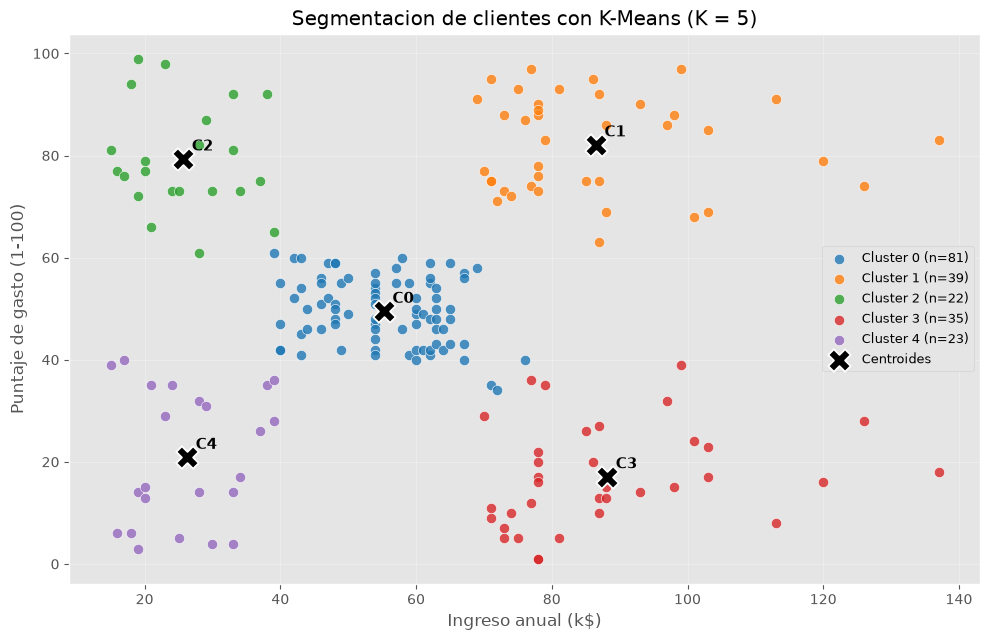

In [17]:
colores_clusters = [plt.cm.tab10(i) for i in range(K_FINAL)]

fig, ax = plt.subplots(figsize=(10, 6.5))
for cluster in range(K_FINAL):
    grupo = df[df["Cluster"] == cluster]
    ax.scatter(
        grupo["Annual Income (k$)"],
        grupo["Spending Score (1-100)"],
        color=colores_clusters[cluster],
        s=55,
        alpha=0.8,
        edgecolors="white",
        linewidths=0.5,
        label=f"Cluster {cluster} (n={len(grupo)})",
    )

ax.scatter(
    centroides_originales["Annual Income (k$)"],
    centroides_originales["Spending Score (1-100)"],
    marker="X",
    s=260,
    color="black",
    edgecolors="white",
    linewidths=1.3,
    label="Centroides",
    zorder=5,
)

for cluster, fila in centroides_originales.iterrows():
    ax.annotate(
        f"C{cluster}",
        xy=(fila["Annual Income (k$)"], fila["Spending Score (1-100)"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold",
    )

ax.set_title("Segmentacion de clientes con K-Means (K = 5)")
ax.set_xlabel("Ingreso anual (k$)")
ax.set_ylabel("Puntaje de gasto (1-100)")
ax.legend(loc="best", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Respuestas — Parte 5

**¿Qué representa cada cluster?**

Cada cluster es un **segmento de clientes con comportamiento similar** en ingreso anual y puntaje de gasto. El centroide es el perfil promedio del segmento: no es un cliente real, sino el punto que resume las características del grupo.

**¿Qué diferencias existen entre los grupos obtenidos?**

| Cluster | Clientes | Perfil observado | Ingreso promedio | Gasto promedio | Edad promedio |
|---|---:|---|---:|---:|---:|
| 0 | 81 | Ingreso y gasto medios | 55.3 k$ | 49.5 | 42.7 años |
| 1 | 39 | Alto ingreso y alto gasto | 86.5 k$ | 82.1 | 32.7 años |
| 2 | 22 | Bajo ingreso y alto gasto | 25.7 k$ | 79.4 | 25.3 años |
| 3 | 35 | Alto ingreso y bajo gasto | 88.2 k$ | 17.1 | 41.1 años |
| 4 | 23 | Bajo ingreso y bajo gasto | 26.3 k$ | 20.9 | 45.2 años |

Las mayores diferencias están en el **gasto**: el cluster 1 gasta en promedio 82.1 puntos, mientras que el 3 solo 17.1. El cluster 0 es el más numeroso (81 clientes, 40.5 %) y representa el comportamiento medio. Los clusters 2 y 4 comparten un ingreso bajo, pero se diferencian radicalmente en el gasto.

## Parte 6 — Interpretación de Negocio

**Actividades:** clasificar los clusters en perfiles como clientes de alto valor, promedio, bajo valor y con potencial.

**Preguntas:**
1. ¿Qué estrategias de marketing se podrían aplicar a cada grupo?
2. ¿Qué segmento representa mayor oportunidad de crecimiento?

In [18]:
perfil_por_cluster = {
    0: "Clientes promedio",
    1: "Clientes de alto valor",
    2: "Clientes con potencial",
    3: "Clientes de bajo valor (alto ingreso)",
    4: "Clientes de bajo valor (bajo ingreso)",
}
df["Perfil"] = df["Cluster"].map(perfil_por_cluster)

porcentaje_mujeres = (
    df.assign(Es_mujer=df["Gender"].eq("Female"))
    .groupby("Cluster")["Es_mujer"]
    .mean()
    .mul(100)
)

resumen_perfiles = (
    df.groupby(["Cluster", "Perfil"])
    .agg(
        Clientes=("CustomerID", "count"),
        Edad_promedio=("Age", "mean"),
        Ingreso_promedio=("Annual Income (k$)", "mean"),
        Gasto_promedio=("Spending Score (1-100)", "mean"),
    )
    .reset_index()
)
resumen_perfiles["Porcentaje"] = 100 * resumen_perfiles["Clientes"] / len(df)
resumen_perfiles["Mujeres_%"] = resumen_perfiles["Cluster"].map(porcentaje_mujeres)
resumen_perfiles = resumen_perfiles[
    ["Cluster", "Perfil", "Clientes", "Porcentaje", "Edad_promedio", "Ingreso_promedio", "Gasto_promedio", "Mujeres_%"]
]
display(resumen_perfiles.round(1))

,Cluster,Perfil,Clientes,Porcentaje,Edad_promedio,Ingreso_promedio,Gasto_promedio,Mujeres_%
0,0,Clientes promedio,81,40.50,42.70,55.30,49.50,59.30
1,1,Clientes de alto valor,39,19.50,32.70,86.50,82.10,53.80
2,2,Clientes con potencial,22,11.00,25.30,25.70,79.40,59.10
3,3,Clientes de bajo valor (alto ingreso),35,17.50,41.10,88.20,17.10,45.70
4,4,Clientes de bajo valor (bajo ingreso),23,11.50,45.20,26.30,20.90,60.90


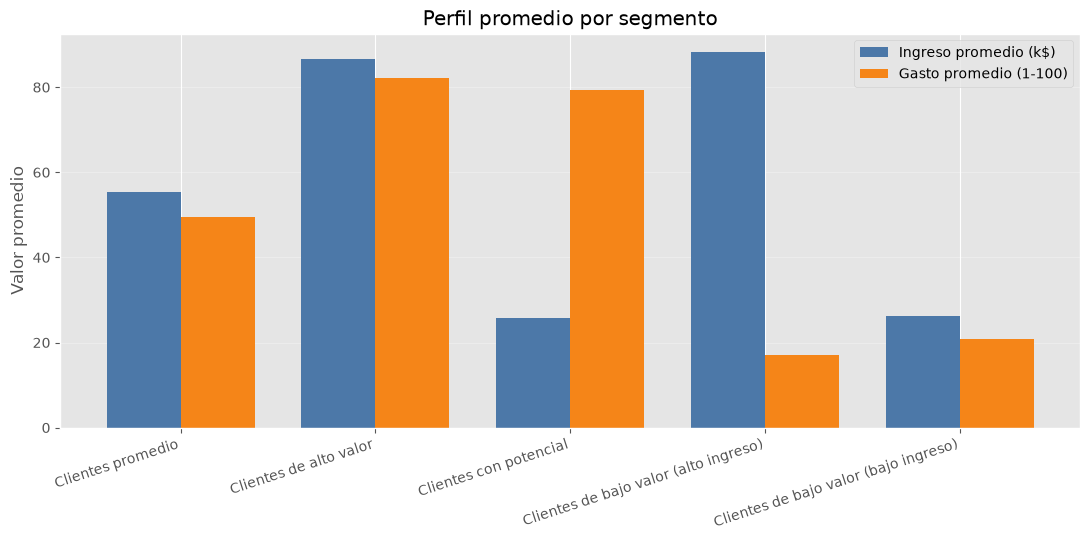

In [19]:
fig, ax = plt.subplots(figsize=(11, 5.5))
posiciones = np.arange(len(resumen_perfiles))
ancho = 0.38

ax.bar(
    posiciones - ancho / 2,
    resumen_perfiles["Ingreso_promedio"],
    width=ancho,
    label="Ingreso promedio (k$)",
    color="#4C78A8",
)
ax.bar(
    posiciones + ancho / 2,
    resumen_perfiles["Gasto_promedio"],
    width=ancho,
    label="Gasto promedio (1-100)",
    color="#F58518",
)
ax.set_xticks(posiciones)
ax.set_xticklabels(resumen_perfiles["Perfil"], rotation=18, ha="right")
ax.set_title("Perfil promedio por segmento")
ax.set_ylabel("Valor promedio")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Perfiles y estrategias de marketing

| Perfil | Cluster | Estrategia sugerida |
|---|---|---|
| **Clientes de alto valor** | 1 | Retención prioritaria: programa de lealtad, beneficios exclusivos, atención personalizada, lanzamientos premium y comunicación uno a uno. Evitar descuentos que erosionen el margen. |
| **Clientes promedio** | 0 | Cross-selling y up-selling, promociones estacionales, programas de puntos y recordatorios de recompra para aumentar la frecuencia y el ticket promedio. |
| **Clientes con potencial** | 2 | Son jóvenes con ingreso bajo pero gasto alto. Ofrecer productos de entrada, pagos a cuotas, experiencias gamificadas y beneficios por referidos; acompañar su crecimiento de ingreso para convertirlos en alto valor. |
| **Bajo valor con alto ingreso** | 3 | Reactivación: ofertas personalizadas, pruebas de productos premium, encuestas para detectar barreras y campañas de recuperación. Tienen capacidad de compra, pero no la están ejerciendo. |
| **Bajo valor con bajo ingreso** | 4 | Estrategia de bajo costo: promociones accesibles, canales digitales, autoservicio y campañas masivas de bajo presupuesto. Priorizar eficiencia, no inversión intensiva. |

**¿Qué segmento representa mayor oportunidad de crecimiento?**

La mayor oportunidad **inmediata** está en el **cluster 3 (bajo valor con alto ingreso)**: son 35 clientes con ingreso promedio de 88.2 k$ pero gasto de solo 17.1. Tienen capacidad de compra desaprovechada, así que aumentar su gasto promedio tiene un impacto directo en ingresos sin necesidad de captar clientes nuevos.

La oportunidad de **largo plazo** está en el **cluster 2 (clientes con potencial)**: 22 clientes jóvenes, con gasto alto (79.4) pero ingreso bajo (25.7). Si se fidelizan ahora, pueden convertirse en clientes de alto valor cuando aumente su ingreso. La combinación de ambas acciones cubre crecimiento inmediato y futuro.

In [20]:
columnas_salida = ["CustomerID", "Gender", "Age", *FEATURES, "Cluster", "Perfil"]
clientes_segmentados = df[columnas_salida].copy()
clientes_segmentados.to_csv("clientes_segmentados.csv", index=False)
print("Archivo generado: clientes_segmentados.csv")
display(clientes_segmentados.head(10))

Archivo generado: clientes_segmentados.csv


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Perfil
0,1,Male,19,15,39,4,Clientes de bajo valor (bajo ingreso)
1,2,Male,21,15,81,2,Clientes con potencial
2,3,Female,20,16,6,4,Clientes de bajo valor (bajo ingreso)
3,4,Female,23,16,77,2,Clientes con potencial
4,5,Female,31,17,40,4,Clientes de bajo valor (bajo ingreso)
5,6,Female,22,17,76,2,Clientes con potencial
6,7,Female,35,18,6,4,Clientes de bajo valor (bajo ingreso)
7,8,Female,23,18,94,2,Clientes con potencial
8,9,Male,64,19,3,4,Clientes de bajo valor (bajo ingreso)
9,10,Female,30,19,72,2,Clientes con potencial


## Parte 7 — Despliegue con Streamlit

**Actividades:** desarrollar una aplicación que permita visualizar el método del codo, mostrar los clusters, ingresar un nuevo cliente y clasificarlo automáticamente.

La aplicación se entrega en el archivo **`app.py`**, ubicado en esta misma carpeta. Incluye:

- Visualización del **método del codo** y del **coeficiente de silueta**.
- Gráfico de los **clusters generados** con sus centroides.
- Tabla resumen de perfiles y estrategias de marketing.
- Formulario para **ingresar un nuevo cliente** (género, edad, ingreso y gasto) y clasificarlo automáticamente.
- Visualización del nuevo cliente sobre el gráfico de segmentos y distancia a cada centroide.
- Descarga de la base segmentada en CSV.

### Cómo ejecutar la aplicación

1. Abra una terminal en esta carpeta.
2. Instale las dependencias (solo la primera vez):

```bash
python -m pip install -r requirements.txt
```

3. Ejecute Streamlit:

```bash
python -m streamlit run app.py
```

4. Se abrirá el navegador en `http://localhost:8501`. Si no se abre automáticamente, copie esa dirección en el navegador.
5. Para detener la aplicación, use `Ctrl + C` en la terminal.

### Despliegue en la nube (opcional)

Para publicar la aplicación en **Streamlit Community Cloud**:

1. Suba a GitHub la carpeta con `app.py`, `Mall_Customers.csv` y `requirements.txt`.
2. Ingrese a Streamlit Community Cloud y conecte su cuenta de GitHub.
3. Seleccione el repositorio, la rama y el archivo `app.py`.
4. Presione **Deploy**. La aplicación obtendrá una URL pública.

In [21]:
from pathlib import Path

for archivo in ["app.py", "requirements.txt", "Mall_Customers.csv", "clientes_segmentados.csv"]:
    print(f"{archivo}: {'encontrado' if Path(archivo).exists() else 'no encontrado'}")

app.py: encontrado
requirements.txt: encontrado
Mall_Customers.csv: encontrado
clientes_segmentados.csv: encontrado


## Conclusiones

- El análisis exploratorio mostró que las variables más informativas para segmentar son el **ingreso anual** y el **puntaje de gasto**; la edad ayuda a describir los perfiles y el género no aporta una separación relevante.
- El escalamiento con `StandardScaler` fue necesario porque K-Means usa distancias euclidianas y el ingreso tiene un rango mucho mayor que el gasto.
- El **método del codo** y el **coeficiente de silueta** coincidieron en **K = 5**. La silueta promedio fue **0.5547**, lo que indica una separación razonable de los segmentos.
- Se identificaron cinco perfiles: alto valor, promedio, con potencial, bajo valor con alto ingreso y bajo valor con bajo ingreso.
- La mayor oportunidad inmediata está en los clientes de **alto ingreso con bajo gasto** (cluster 3), mientras que los clientes jóvenes de **bajo ingreso con alto gasto** (cluster 2) representan la oportunidad de crecimiento futuro.
- La aplicación en Streamlit permite explorar el modelo, visualizar los segmentos y clasificar nuevos clientes, facilitando el uso de los resultados para decisiones de marketing.

### Limitaciones

El dataset no incluye variables transaccionales como frecuencia de compra, ticket promedio o margen, por lo que los perfiles son descriptivos. Además, es una muestra pequeña (200 clientes) y estática; en un caso real conviene reentrenar periódicamente y validar los segmentos con datos de negocio.